# On the limited benefits of thermal plasticity across latitudes

Alex Gunderson (Tulane University)  
Guillermo Garcia-Costoya (University of Nevada, Reno)  
Michael L. Logan (University of Nevada, Reno)

Phenotypic plasticity is a ubiquitous feature of organisms

In [ ]:
# load packages
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.1     ✔ stringr   1.5.2
✔ ggplot2   4.0.0     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.1.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

## Introduction

Phenotypic plasticity is a ubiquitous feature of organisms that plays a key role in adaptation and responses to global change. As such, there is a great deal of interest in understanding how phenotypic plasticity evolves. In general, adaptive phenotypic plasticity is expected to evolve when environmental conditions fluctuate in a predictable manner. In many cases this expectation is met, but in many others it is not. Why not is an open question.

Often overlooked when predicting the evolution of phenotypic plasticity is the fact that plasticity is not the only means of dealing with fluctuating environmental conditions. Rather than inducing a plastic response, organisms can evolve a constitutive phenotype that does well over a broad range of conditions. Under what conditions organisms should evolve inducible versus constitutive strategies (or some combination of the two) to adapt to environmental variation is an area of considerable work that is beyond our scope. However, recognizing that both plasticity and constitutive breadth are alternate solutions to the same problem is important. What this tells us is that our expectations for the evolution of plasticity should depend not just on the scale and predictability of environmental variation, but on the constitutive phenotypic breadth of the organisms under consideration.

Here, we explore how environmental variation and constitutive breadth interact to determine the evolutionary benefits of phenotypic plasticity. This work is motivated by our interest in thermal adaptation and the evolution of thermal tolerance plasticity in ectothermic animals. Plasticity in thermal physiology, such tolerance and sensitivity to heat and cold, is hypothesized to be greatest in areas with high levels of temporal variation in temperature (the Climate Variability Hypothesis, CVH). This leads to the prediction that ectotherms in the tropics should evolve less plasticity in thermal physiology than those at high latitude. Surprisingly, the CVH has little support. Analyses at many phylogenetic and geographic scales have found no relationship between plasticity in thermal physiology and latitude, and sometimes even find greater plasticity at low latitudes (Angilletta 2009, others). Similarly, analyses that directly test for links between thermal plasticity and environmental temperature variation have found no pattern, mixed support for the CVH, or a pattern inverse to the CVH.

The CVH is an intuitive hypothesis, and at first glance the lack of support for it is surprising. However, the predictions of the CVH are based on knowledge of environmental temperature dynamics alone. What these predictions do not weigh is a prominent pattern in ectotherm thermal physiology that does span latitude and other thermal gradients: animals that live in more variable thermal environments evolve greater constitutive thermal tolerance breadths (Sunday, others). For example, ectotherms at higher latitudes tolerate a wider range of temperatures than those in the low latitude tropics, and have broader thermal performance curves (see below) that make them less sensitive to temperature change. This is crucial, and may help explain why high latitude taxa do not consistently evolve greater thermal plasticity. In the next section, we begin with a simple demonstration of how before moving on to more complex scenarios.

## The basics

We begin by considering two ectothermic organisms with asymmetrical **thermal performance curves** (TPCs) with narrow and wide constitutive thermal breadths, representing a tropical and high latitude ectotherm, respectively (Figure 1). For simplicity, first assume that each organism experiences a constant body temperature that is equal to the temperature that maximizes its fitness (i.e., the optimal temperature, T<sub>opt</sub>, set to 30 <sup>o</sup>C, for this example). Next, assume that both organisms experience the same amount of change in body temperature (e.g., an increase of 3 <sup>o</sup>C due to warming environmental conditions). In the abscence of any plasticity, both organisms will experience a decrease in fitness because their body temperatures exceed their T<sub>opt</sub>. However, the tropical organism will experience a much greater decrease in fitness than the high-latitude organism because it has a narrower TPC (black dashed lines in Figure 1). Now, assume that both organisms are capable of undergoing an adaptive plastic shift in their TPCs such that their fitness at the new body temperature increases (red TPCs in Figure 1). We know that thermal plasticity does not yield perfect compensation for temperature change, and this **acclimation response ratio** (ARR) is between 10 and 50% of the experienced change in body temperature (Cite). In this example, we assume an ARR of 30% for both TPCs, such that all the constituent traits of the TPCs shift by 0.3 <sup>o</sup>C each 1 <sup>o</sup>C increase in body temperature.

There are two key patterns of note here. First, the tropical organism gains a greater fitness benefit from plasticity than the high latitude organism (red dashed line and red arrow). Recall that in this hypothetical example, both organism experience the same increase in body temperature and exhibit the same level of plasticity. Therefore, all else being equal, organisms with narrower constitutive breadths benefit the most from phenotypic plasticity. Second, although the net benefit of a given amount of plasticity is greater for the tropical species, the absolute fitness value remains lower after the plastic shift. As such, all else equal, organisms with narrow TPCs need to exhibit greater plasticity than organisms with broad TPCs to maintain a similar level of fitness when conditions change.

In [ ]:
# thermal performance curve (tpc)
tpc <- function(temps, topt, ctmin, ctmax) {

  # initialize performance vector and define psig
  perf <- rep(NA, length(temps))
  psig <- -((ctmin - topt) / 4)

  # calculate performance
  for (i in seq_along(temps)){
    if (temps[i] < topt) {
      perf[i] <- exp(-((temps[i] - topt) / (2 * psig))^2)
    } else {
      perf[i] <- 1 - ((temps[i] - topt) / (topt - ctmax))^2
    }
  }

  # correct for negative values and return
  ifelse(perf < 0, 0, perf)

}

# define general parameters for tpcs
temps <- seq(0, 50, by = 0.1) # temperature range
delta_temp <- 4 # change in temperature
arr <- 0.3 # acclimation response ratio (ARR) for plasticity

# create tpcs with and without plasticity for broad and narrow breadths
tpc_broad <- tpc(temps, topt = 30, ctmin = 5, ctmax = 40)
tpc_broad_plastic <- tpc(
  temps, topt = 30 + arr * delta_temp,
  ctmin = 5 + arr * delta_temp,
  ctmax = 40 + arr * delta_temp
)
tpc_narrow <- tpc(temps, topt = 30, ctmin = 20, ctmax = 35)
tpc_narrow_plastic <- tpc(
  temps, topt = 30 + arr * delta_temp,
  ctmin = 20 + arr * delta_temp,
  ctmax = 35 + arr * delta_temp
)

# create data frame for plotting
tpc_df <- data.frame(
  temps = rep(temps, 4),
  performance = c(tpc_broad, tpc_broad_plastic,
                  tpc_narrow, tpc_narrow_plastic),
  curve_breadth = rep(c("Wide TPC", "Wide TPC",
                        "Narrow TPC", "Narrow TPC"),
                      each = length(temps)),
  plasticity = rep(c("No Plasticity", "With Plasticity",
                     "No Plasticity", "With Plasticity"), each = length(temps))
)

# prepare segments data frame
segments_df <- data.frame(
  x = c(0, 0, 0, 0),
  xend = c(30 + delta_temp, 30 + delta_temp, 30 + delta_temp, 30 + delta_temp),
  y = c(
    tpc_broad[temps == (30 + delta_temp)],
    tpc_broad_plastic[temps == (30 + delta_temp)],
    tpc_narrow[temps == (30 + delta_temp)],
    tpc_narrow_plastic[temps == (30 + delta_temp)]
  ),
  yend = c(
    tpc_broad[temps == (30 + delta_temp)],
    tpc_broad_plastic[temps == (30 + delta_temp)],
    tpc_narrow[temps == (30 + delta_temp)],
    tpc_narrow_plastic[temps == (30 + delta_temp)]
  ),
  curve_breadth = rep(c("Wide TPC", "Wide TPC",
                        "Narrow TPC", "Narrow TPC"),
                      each = 1),
  plasticity = rep(c("No Plasticity", "With Plasticity",
                     "No Plasticity", "With Plasticity"),
                   each = 1)
)

# prepare arrows data frame
arrows_df <- data.frame(
  x = c(10, 10),
  xend = c(10, 10),
  y = c(
    tpc_broad[temps == (30 + delta_temp)] + 0.01,
    tpc_narrow[temps == (30 + delta_temp)] + 0.01
  ),
  yend = c(
    tpc_broad_plastic[temps == (30 + delta_temp)] - 0.01,
    tpc_narrow_plastic[temps == (30 + delta_temp)] - 0.01
  ),
  curve_breadth = c("Wide TPC", "Narrow TPC")
)

# plot the phenomenon
tpc_df |>
  ggplot(aes(x = temps, y = performance, color = plasticity)) +
  annotate(
    geom = "segment", x = 30, xend = 30 + delta_temp, y = 0.05, yend = 0.05,
    arrow = arrow(length = unit(0.2, "cm")), linewidth = 1.25, color = "darkorange" # nolint
  ) +
  annotate(
    geom = "point", x = 30, y = 0.05, size = 2, color = "darkorange"
  ) +
  geom_vline(
    xintercept = 30 + delta_temp,
    color = "darkorange", alpha = 0.25, linewidth = 1.5
  ) +
  geom_vline(xintercept = 30, alpha = 0.25, linewidth = 1.5, color = "gray") +
  geom_line(linewidth = 1.25) +
  geom_segment(data  = segments_df,
               aes(x = x, y = y, xend = xend, yend = yend),
               linetype = "dashed", linewidth = 1) +
  geom_segment(data  = arrows_df,
               aes(x = x, y = y, xend = xend, yend = yend),
               arrow = arrow(length = unit(0.2, "cm")),
               color = "darkred", linewidth = 1) +
  scale_color_manual(values = c("black", "darkred")) +
  facet_wrap(~curve_breadth, nrow = 1, axes = "all") +
  scale_x_continuous(expand = c(0, 0)) +
  scale_y_continuous(expand = c(0, 0), limits = c(0, 1.025)) +
  theme_classic() +
  theme(
    strip.text = element_text(size = 12, hjust = 0, face = "bold"),
    strip.background = element_blank(),
    legend.text = element_text(size = 12),
    legend.title = element_blank(),
    legend.margin = margin(l = -30)
  ) +
  labs(
    x = expression("Body Temperature (" * degree * "C)"),
    y = "Fitness (W)",
  )

In fact, to maintan the same level of fitness after a substantial increase in body temperature, the tropical organism would need to exhibit a much greater level of plasticity than the high latitude organism (Figure 2). For example, to match the fitness of the wide TPC at an ARR of 30% after a 3°C increase in body temperature, the narrow TPC needs to exhibit an ARR of 65%. This is a substantial difference in plasticity, and it is not clear that such a high level of plasticity is even possible.

In [ ]:
# define sequence of ARRs to test
arrs <- seq(0, 1, by = 0.01)
orginal_temp <- 30
delta_temp <- 3

# calculate TPC fitness across ARRs for broad TPC
w_broad <- lapply(arrs, function(x) {
  tpc(
    temps = orginal_temp + delta_temp,
    topt = orginal_temp + x * delta_temp,
    ctmin = 5 + x * delta_temp,
    ctmax = 40 + x * delta_temp
  )
}) |> unlist()
w_narrow <- lapply(arrs, function(x) {
  tpc(
    temps = orginal_temp + delta_temp,
    topt = orginal_temp + x * delta_temp,
    ctmin = 20 + x * delta_temp,
    ctmax = 35 + x * delta_temp
  )
}) |> unlist()

# create data frame for plotting
arr_df <- data.frame(
  arr = arrs,
  w_broad = w_broad,
  w_narrow = w_narrow
) |>
  pivot_longer(
    cols = c(w_broad, w_narrow),
    names_to = "curve_breadth",
    values_to = "fitness"
  ) |>
  mutate(
    curve_breadth = recode(curve_breadth,
                           w_broad = "Wide TPC",
                           w_narrow = "Narrow TPC")
  )

# find at which ARR the fitness of the narrow TPC is equal to the fitness of
# the broad TPC at ARR = 0.3
w_broad_30 <- arr_df |>
  filter(curve_breadth == "Wide TPC", arr == 0.3) |>
  pull(fitness)
arr_narrow_equal <- arr_df |>
  filter(curve_breadth == "Narrow TPC", fitness >= w_broad_30) |>
  slice(1) |>
  pull(arr)

# plot the phenomenon
arr_df |>
  ggplot(aes(x = arr, y = fitness, color = curve_breadth)) +
  geom_line(linewidth = 1.25) +
  annotate(
    geom = "segment",
    x = 0, xend = arr_narrow_equal, y = w_broad_30, yend = w_broad_30
  ) +
  annotate(
    geom = "segment",
    x = 0.3, xend = 0.3, y = -Inf, yend = w_broad_30,
    color = "#56B4E9", linetype = "dashed"
  ) +
  annotate(
    geom = "point", x = 0.3, y = w_broad_30, size = 2, color = "#56B4E9"
  ) +
  annotate(
    geom = "point",
    x = arr_narrow_equal, y = w_broad_30, size = 2, color = "#E69F00"
  ) +
  annotate(
    geom = "segment",
    x = arr_narrow_equal, xend = arr_narrow_equal, y = -Inf, yend = w_broad_30,
    linetype = "dashed", color = "#E69F00"
  ) +
  scale_color_manual(values = c("#E69F00", "#56B4E9")) +
  scale_x_continuous(
    expand = c(0, 0),
    breaks = seq(0, 1, 0.1),
    labels = scales::percent_format(accuracy = 1)
  ) +
  theme_classic() +
  theme(
    legend.text = element_text(size = 12),
    legend.title = element_blank(),
    legend.margin = margin(l = -70, b = -110)
  ) +
  labs(
    x = "Acclimation Response Ratio (ARR)",
    y = "Fitness after a 3°C increase in Tb"
  )

## Incorporating variability in body temperature

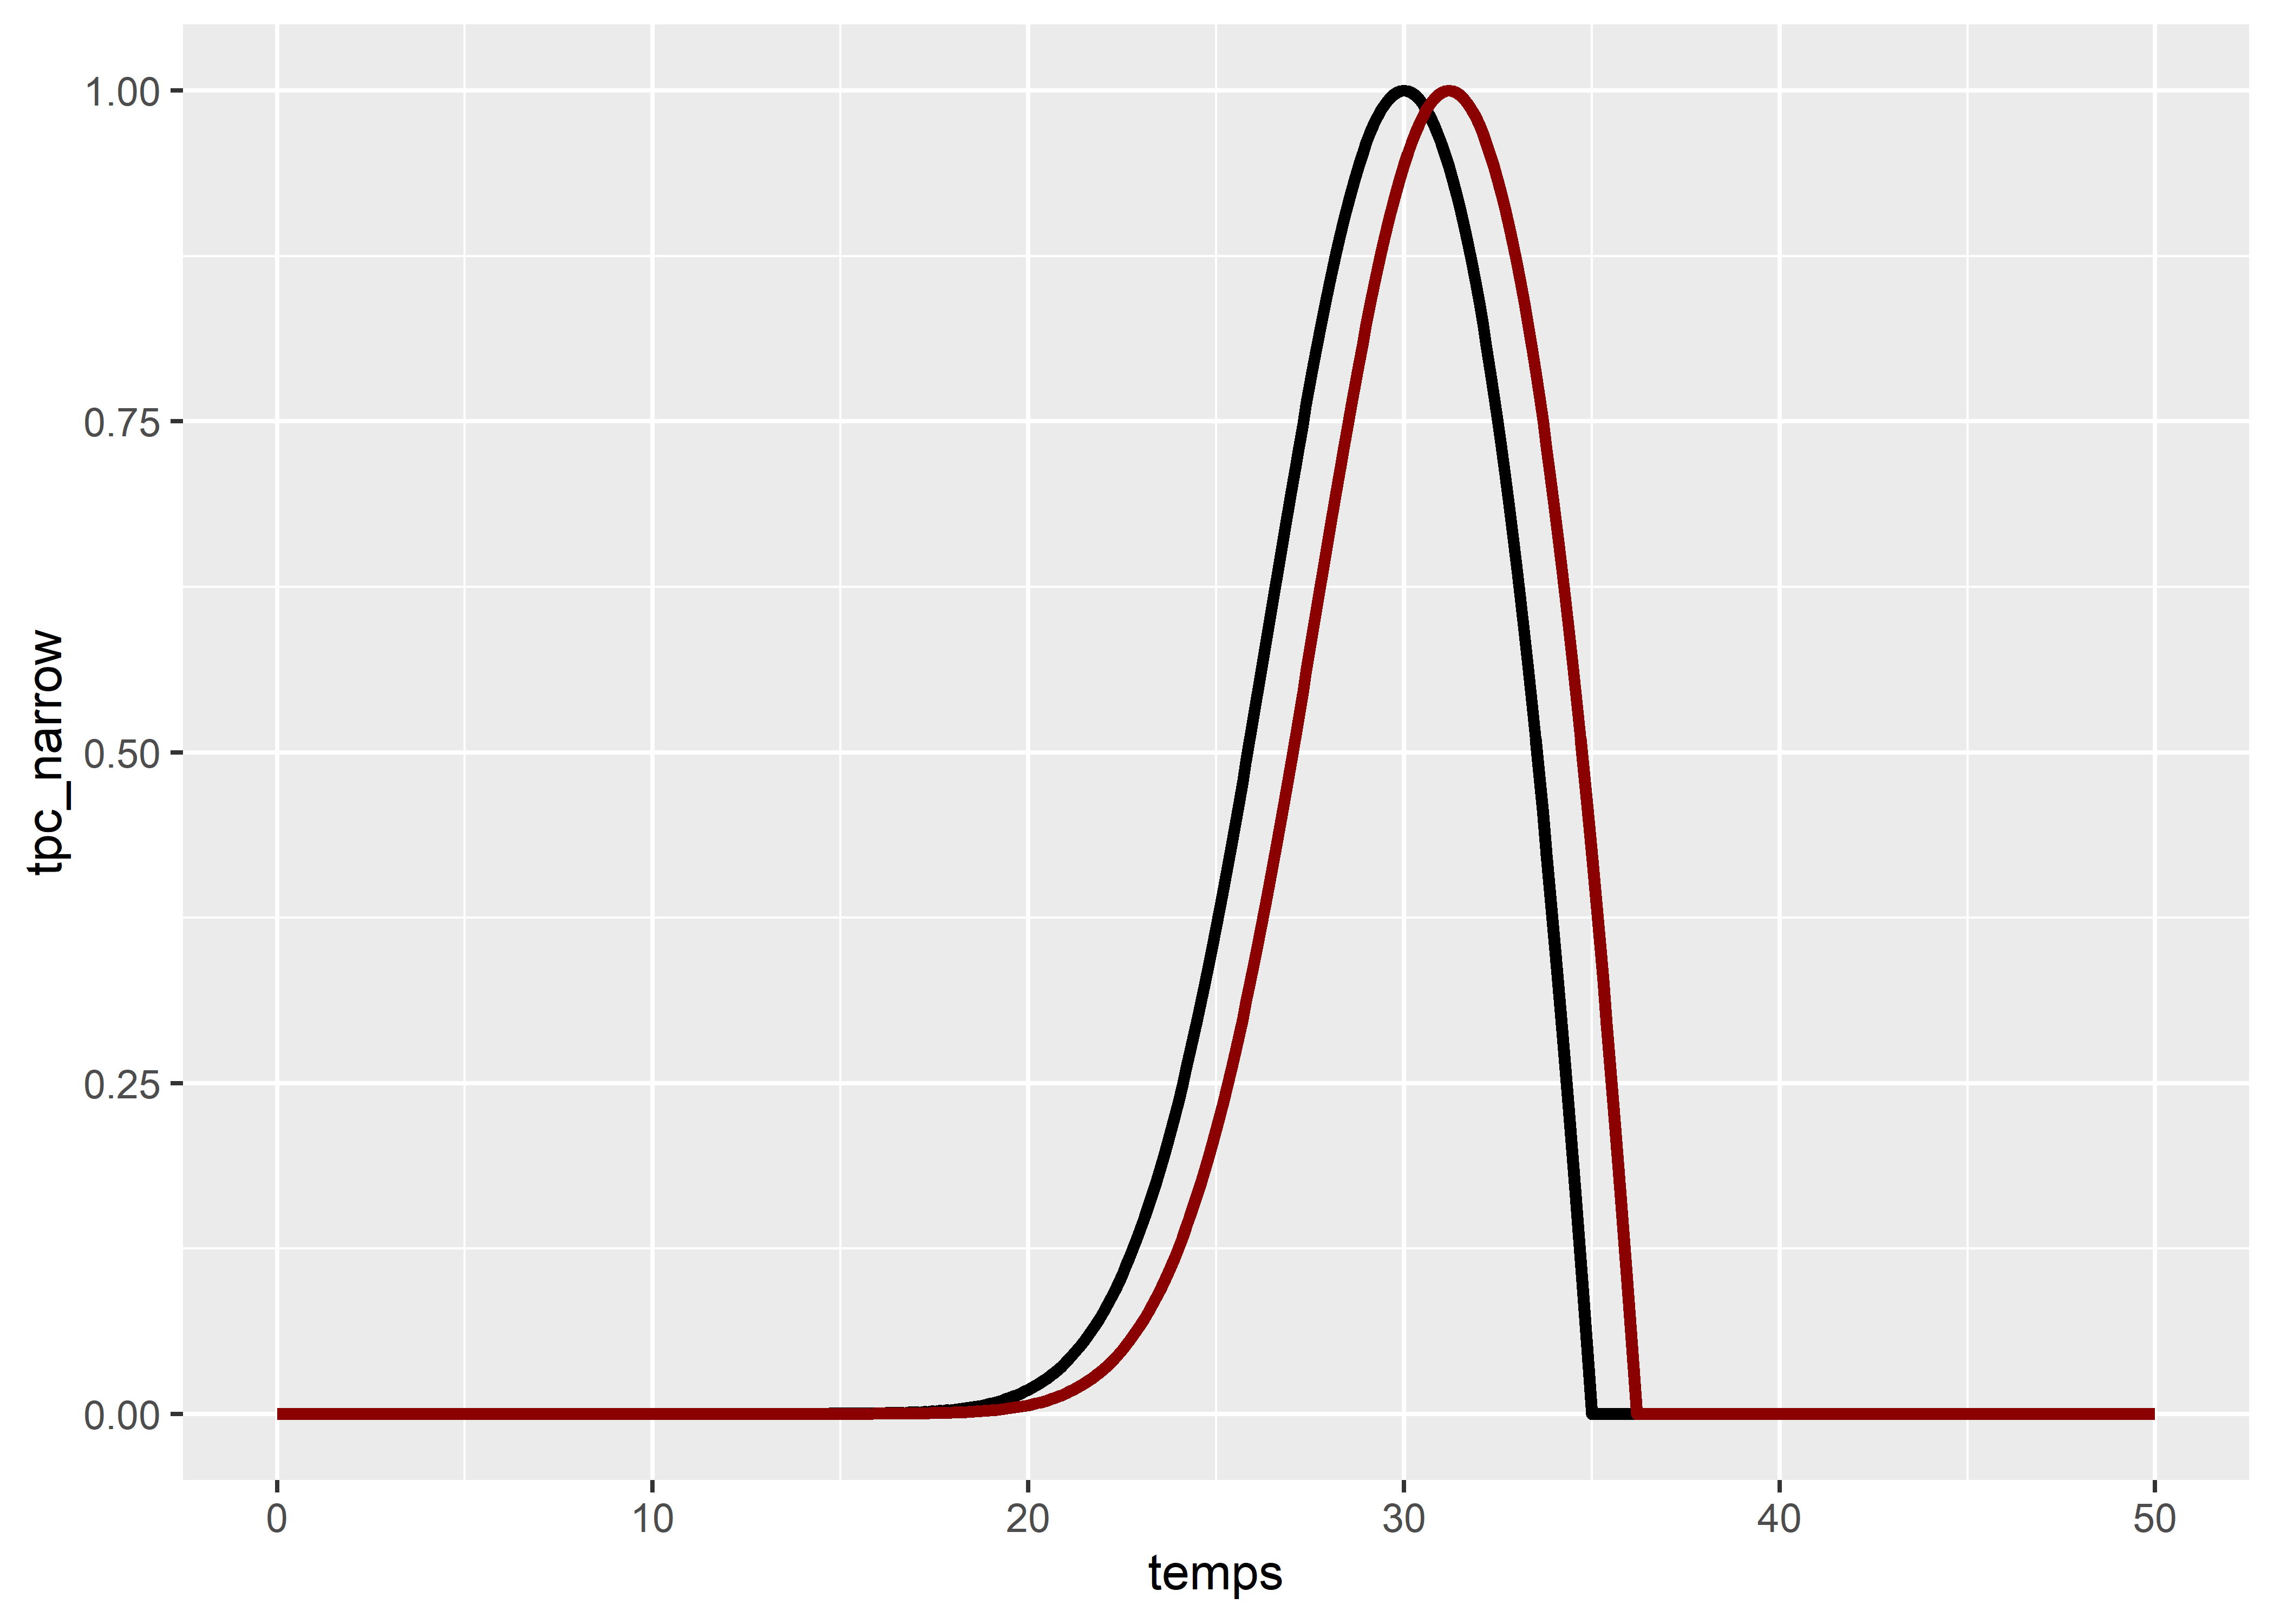

In [ ]:
# define expected fitness function using Vasseur method
exp_w <- function(topt, ctmin, ctmax, mean_tb, sd_tb) {

  if (sd_tb == 0) {
    tpc(mean_tb, topt, ctmin, ctmax)

  } else {
    # function to calculate integrand
    integrand <- function(temps) {
      tpc(temps, topt, ctmin, ctmax) * dnorm(temps, mean = mean_tb, sd = sd_tb)
    }

    # integrate
    integrate(integrand, lower = -30, upper = 60)$value
  }
}

# calculate expected fitness of narrow TPC with and without thermal variability
ggplot() +
  geom_line(aes(x = temps, y = tpc_narrow), color = "black", linewidth = 1.25) +
  geom_line(aes(x = temps, y = tpc_narrow_plastic), color = "darkred", linewidth = 1.25) # nolint

## Additional methods

#### Thermal performance curve function

#### Expected fitness calculation

#### Risk of thermal injury

#### Generating unique TPCs and initial body temperature distributions

#### Optimal thermal safety margins

#### Changes in body temperature distributions and acclimation response ratios

#### Benefits of plasticity

#### Software and code availability

## References